In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.stattools import acf, pacf, adfuller

from scipy.stats import pearsonr, spearmanr

import json
import sys
from pathlib import Path

In [2]:
sys.path.append(str(Path.cwd().parent))

from src.config import (
    file_names,
    target,
    predictors,
    variables,
    numerical_cols,
    sentinel_col
)

In [3]:
for file in file_names:
    print(f"\n{'='*25}")
    print(f"FILE: {file}")
    print(f"{'='*25}")

    PROJECT_ROOT = Path.cwd().parent
    DATA_DIR = PROJECT_ROOT / "data" / "raw"
    
    df_check = pd.read_csv(DATA_DIR / file)

    print("Shape:", df_check.shape)
    print("\nColumns:", df_check.columns.tolist())
    print("\nThe first 5 rows:\n", df_check.head())
    print("\nData type:\n", df_check.dtypes)
    print("\nMissing values:\n", df_check.isnull().sum())
    print("\nDuplicates rows:\n", df_check.duplicated().sum())


FILE: combined_gee_pm25.csv
Shape: (41718, 15)

Columns: ['date', 'datetime_utc', 'id', 'latitude', 'longitude', 'temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'NO2', 'CO', 'O3', 'AOD', 'pm25', 'sensor_name']

The first 5 rows:
          date         datetime_utc  id   latitude  longitude  \
0  2016-11-25  2016-11-25 00:00:00   1  38.788056  -0.697222   
1  2016-11-25  2016-11-25 00:00:00  36  39.945278  -0.056389   
2  2016-11-30  2016-11-30 00:00:00  35  40.051944  -0.189722   
3  2016-11-30  2016-11-30 00:00:00  37  40.062222   0.072778   
4  2016-12-02  2016-12-02 00:00:00   1  38.788056  -0.697222   

   temperature_celsius  pressure_mb    wind_u    wind_v  NO2  CO  O3     AOD  \
0             6.493180   946.288660  0.230240  0.735303  NaN NaN NaN  0.1110   
1             9.251236   993.626994  0.783218 -0.592618  NaN NaN NaN  0.0220   
2            10.044782   981.911432 -2.211047 -1.568971  NaN NaN NaN  0.2380   
3            12.299584  1008.794766 -3.236886 -2.80446

In [4]:
df = pd.read_csv("../data/combined_gee_pm25.csv")

df["date"] = pd.to_datetime(df["date"], errors="coerce")

FileNotFoundError: [Errno 2] No such file or directory: '../data/combined_gee_pm25.csv'

In [ ]:
print("\nMain dataset info:")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Target:", target)
print("Date range:", df["date"].min(), "to", df["date"].max())

print("\nLatitude range:")
print(df["latitude"].min(), df["latitude"].max())

print("\nLongitude range:")
print(df["longitude"].min(), df["longitude"].max())

print("\nDataset information:")
df.info()

print("\nDescribe:\n", df[target].describe())


Main dataset info:
Shape: (41718, 15)
Columns: ['date', 'datetime_utc', 'id', 'latitude', 'longitude', 'temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'NO2', 'CO', 'O3', 'AOD', 'pm25', 'sensor_name']
Target: pm25
Date range: 2016-11-25 00:00:00 to 2026-04-06 00:00:00

Latitude range:
36.13331699932336 43.5302972250095

Longitude range:
-5.663499999930786 9.136389000276088

Dataset information:


<class 'pandas.DataFrame'>
RangeIndex: 41718 entries, 0 to 41717
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   date                 41718 non-null  datetime64[us]
 1   datetime_utc         41718 non-null  str           
 2   id                   41718 non-null  int64         
 3   latitude             41718 non-null  float64       
 4   longitude            41718 non-null  float64       
 5   temperature_celsius  41718 non-null  float64       
 6   pressure_mb          41718 non-null  float64       
 7   wind_u               41718 non-null  float64       
 8   wind_v               41718 non-null  float64       
 9   NO2                  39308 non-null  float64       
 10  CO                   39308 non-null  float64       
 11  O3                   39267 non-null  float64       
 12  AOD                  41718 non-null  float64       
 13  pm25                 41718 non-null  float

In [ ]:
summary = df[numerical_cols].describe().T

summary["skewness"] = df[numerical_cols].skew()
summary["kurtosis"] = df[numerical_cols].kurt()

print("\nDescribe:\n", summary.round(2))


Describe:
                        count    mean    std     min     25%     50%      75%  \
latitude             41718.0   39.03   2.23   36.13   36.84   39.45    40.05   
longitude            41718.0   -0.47   3.82   -5.66   -3.61   -0.41     1.15   
temperature_celsius  41718.0   18.33   6.38   -1.28   13.02   18.59    23.86   
pressure_mb          41718.0  993.70  17.24  930.32  987.76  997.64  1005.29   
wind_u               41718.0    0.34   2.52  -11.10   -0.99    0.19     1.67   
wind_v               41718.0   -0.17   1.38  -10.86   -0.72    0.05     0.66   
NO2                  39308.0    0.00   0.00    0.00    0.00    0.00     0.00   
CO                   39308.0    0.03   0.00    0.01    0.03    0.03     0.03   
O3                   39267.0    0.14   0.01    0.10    0.13    0.14     0.15   
AOD                  41718.0    0.15   0.11    0.00    0.08    0.13     0.20   
pm25                 41718.0    9.10  23.14 -999.00    4.50    7.75    12.00   

                         ma

In [ ]:
print("\nObservation per sensor:")
print(df["sensor_name"].value_counts())

print("\nNumber of unique sensors:")
print(df["sensor_name"].nunique())


Observation per sensor:
sensor_name
CENMO1                           1047
CENCA1                           1042
MOMPEAN                           894
ALBALAT DELS TARONGERS            818
SAGUNT CEA                        817
                                 ... 
testcompnex                         4
mimiz                               4
Rosia Road                          4
Barcelona - Camp d'en Grassot       4
064F                                1
Name: count, Length: 94, dtype: int64

Number of unique sensors:
94


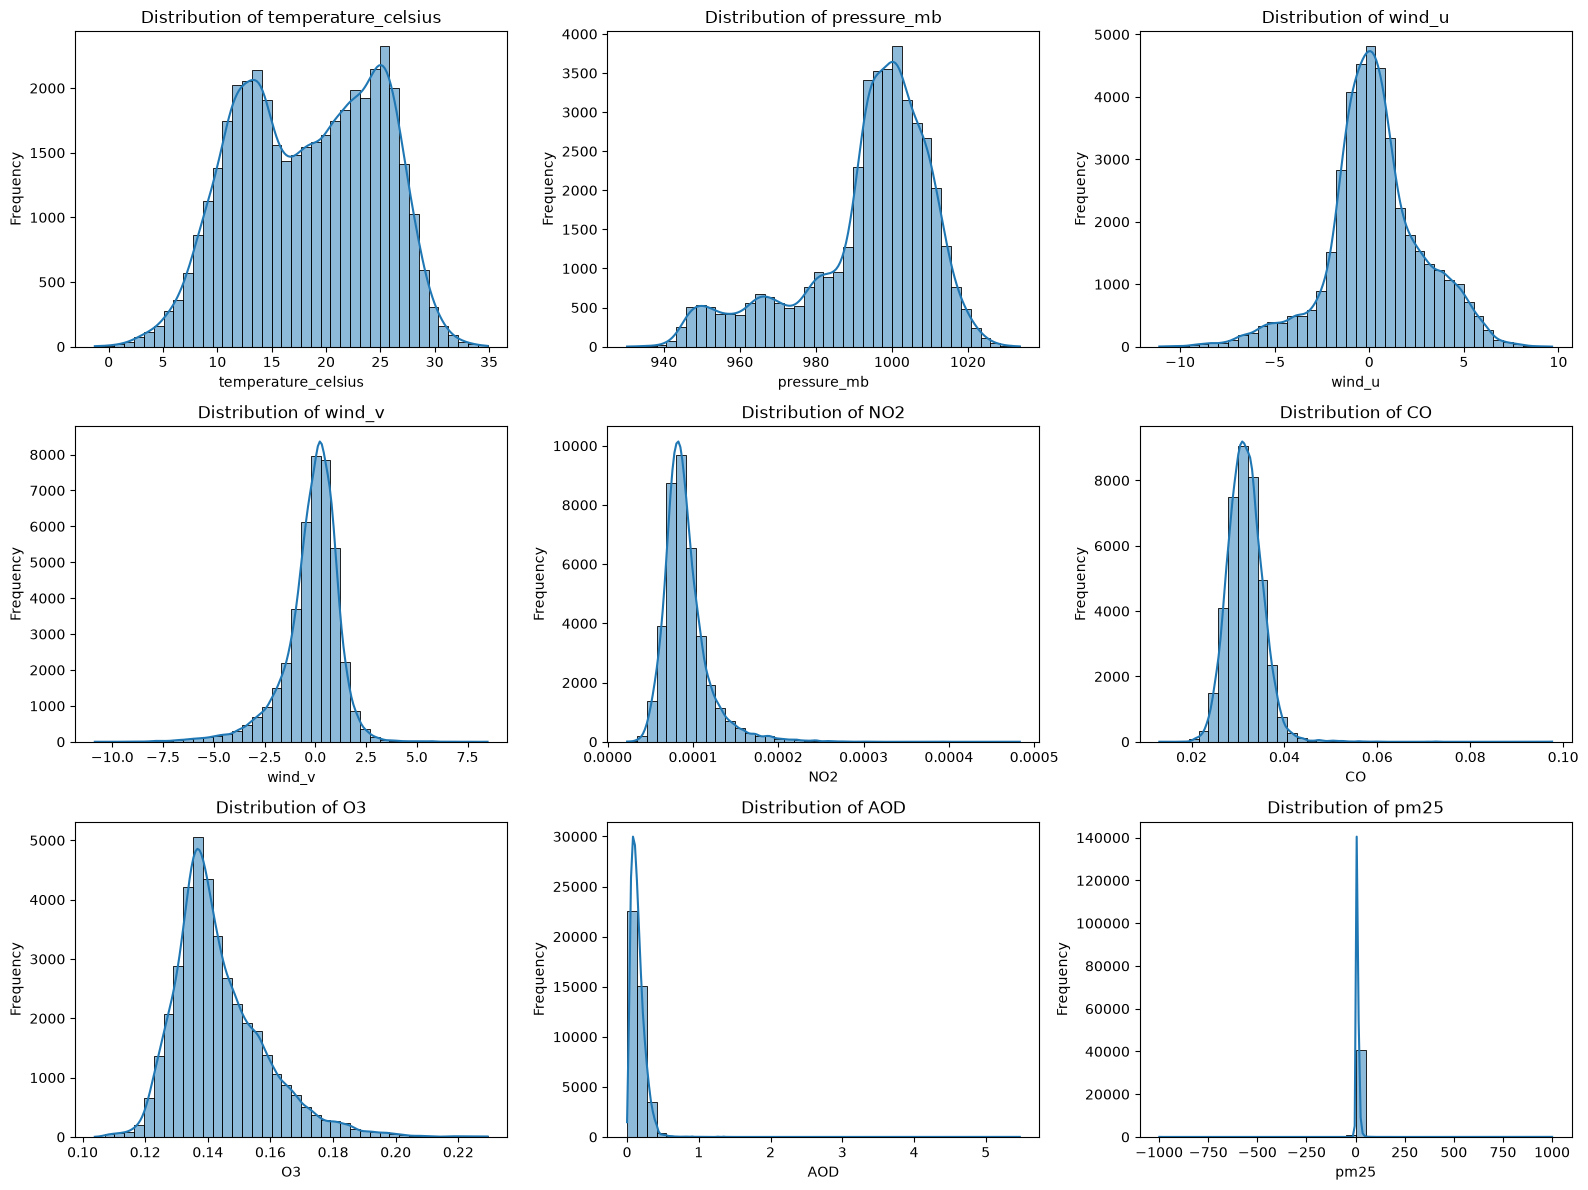

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(variables):
    sns.histplot(data=df, x=col, bins=40, kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

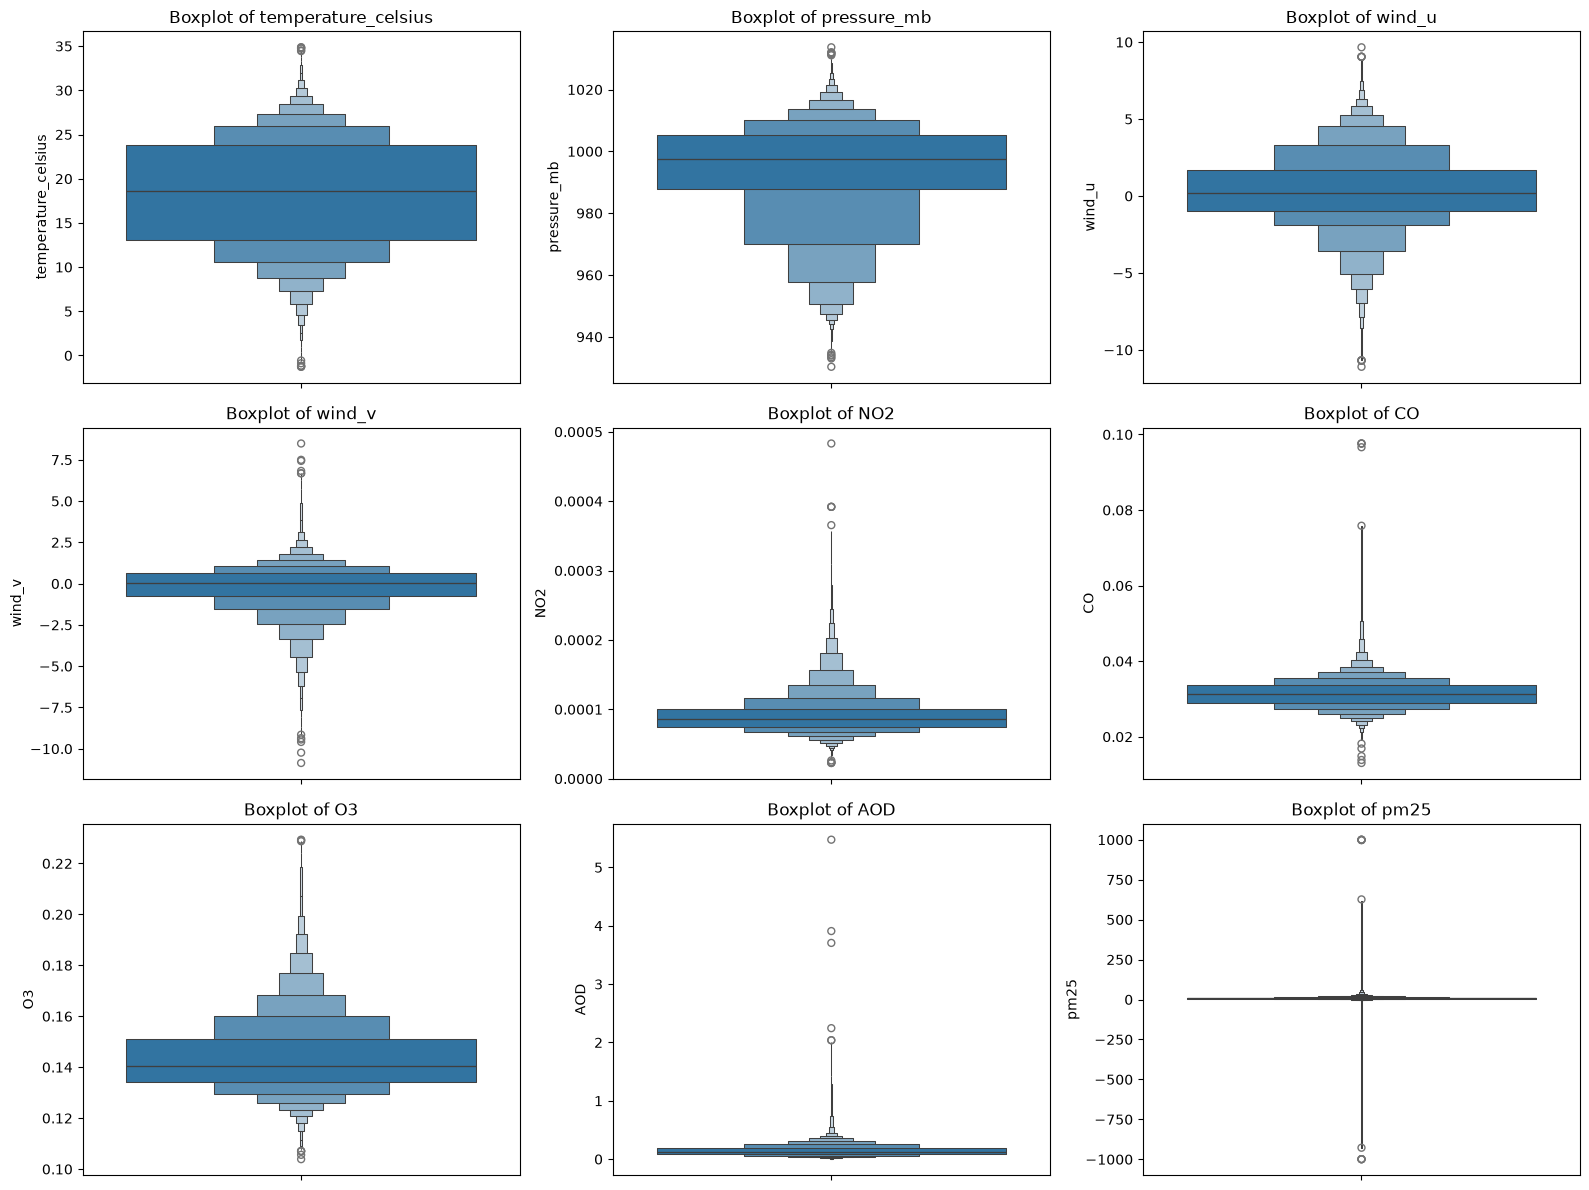

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(variables):
    sns.boxenplot(data=df, y=col, ax=axes[i])
    axes[i].set_title(f"Boxplot of {col}")
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

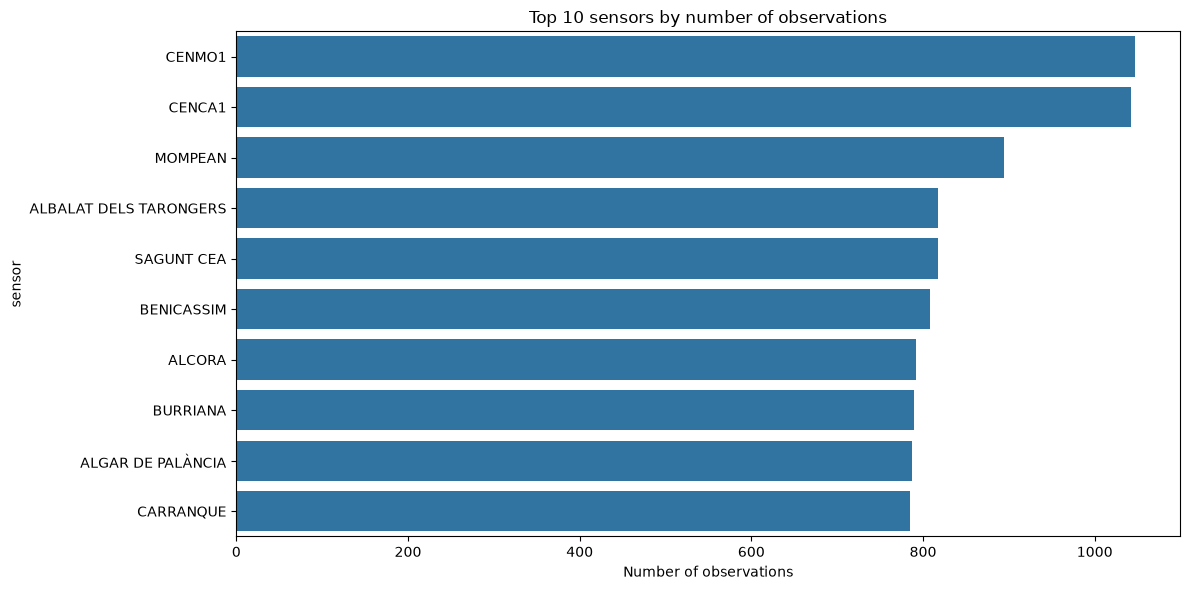

In [ ]:
top_sensors = df["sensor_name"].value_counts().head(10).index

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df[df["sensor_name"].isin(top_sensors)],
    y="sensor_name",
    order=top_sensors
)

plt.title("Top 10 sensors by number of observations")
plt.xlabel("Number of observations")
plt.ylabel("sensor")

plt.tight_layout()
plt.show()

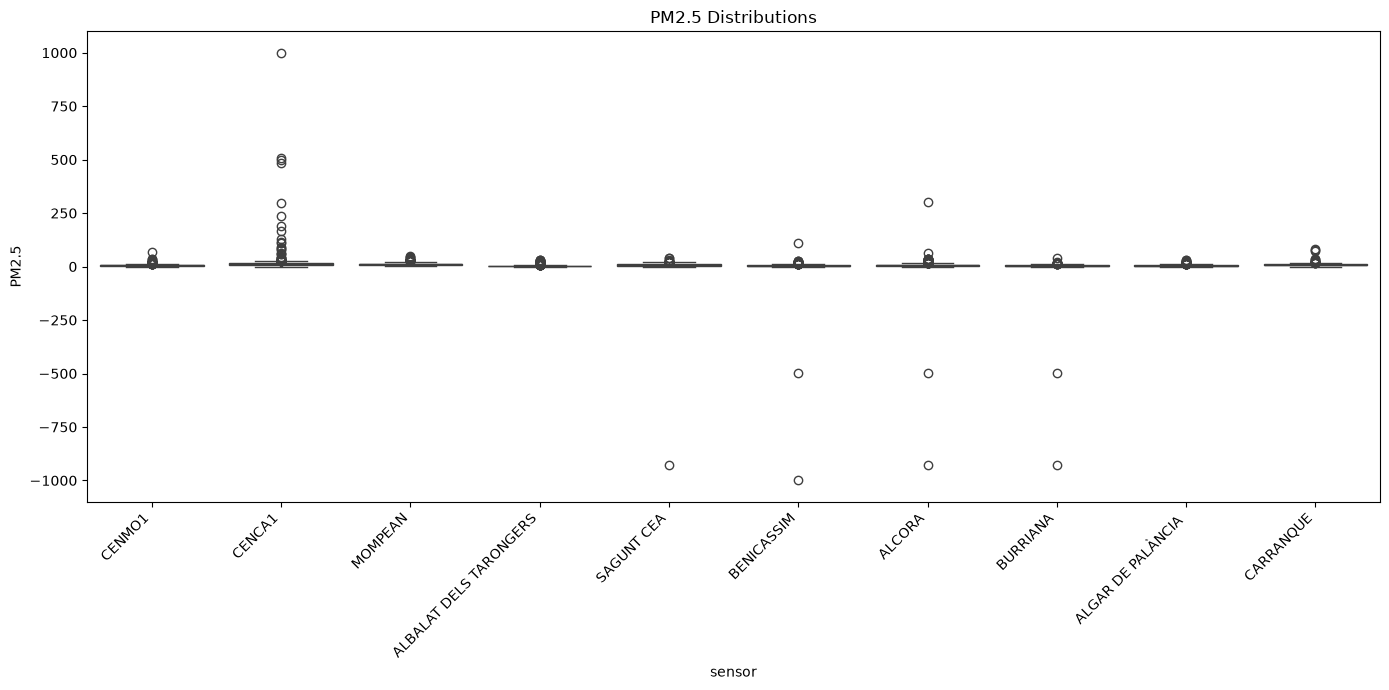

In [ ]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df[df["sensor_name"].isin(top_sensors)],
    x="sensor_name",
    y=target,
    order=top_sensors
)

plt.title("PM2.5 Distributions")
plt.xlabel("sensor")
plt.ylabel("PM2.5")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [ ]:
print("\nMissing count:\n", df.isnull().sum())

print(
    "\nMissing percentage:\n",
    (df.isnull().mean() * 100).round(2)
)


Missing count:
 date                      0
datetime_utc              0
id                        0
latitude                  0
longitude                 0
temperature_celsius       0
pressure_mb               0
wind_u                    0
wind_v                    0
NO2                    2410
CO                     2410
O3                     2451
AOD                       0
pm25                      0
sensor_name               0
dtype: int64

Missing percentage:
 date                   0.00
datetime_utc           0.00
id                     0.00
latitude               0.00
longitude              0.00
temperature_celsius    0.00
pressure_mb            0.00
wind_u                 0.00
wind_v                 0.00
NO2                    5.78
CO                     5.78
O3                     5.88
AOD                    0.00
pm25                   0.00
sensor_name            0.00
dtype: float64


In [ ]:
print("\nDomain knowledge check:")

print("Negative PM2.5 values:", (df[target] < 0).sum())
print("PM2.5 values equal to -999:", (df[target] == -999).sum())
print("PM2.5 values equal to 1000:", (df[target] == 1000).sum())

print("Negative AOD values:", (df["AOD"] < 0).sum())
print(
    "Negative pressure values:",
    (df["pressure_mb"] < 0).sum()
)


Domain knowledge check:
Negative PM2.5 values: 273
PM2.5 values equal to -999: 4
PM2.5 values equal to 1000: 2
Negative AOD values: 0
Negative pressure values: 0


In [ ]:
print("\nIQR:")

iqr_results = []

for col in variables:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    iqr_results.append({
        "variable": col,
        "Lower bound": lower,
        "Upper bound": upper,
        "Outliers": outliers,
        "Percentage": outliers / len(df) * 100
    })

iqr_table = pd.DataFrame(iqr_results)

print(iqr_table.round(2).to_string(index=False))


IQR:
           variable  Lower bound  Upper bound  Outliers  Percentage
temperature_celsius        -3.25        40.13         0        0.00
        pressure_mb       961.46      1031.59      3202        7.68
             wind_u        -4.99         5.67      2185        5.24
             wind_v        -2.80         2.74      2290        5.49
                NO2         0.00         0.00      2096        5.02
                 CO         0.02         0.04       573        1.37
                 O3         0.11         0.18      1263        3.03
                AOD        -0.09         0.37      1099        2.63
               pm25        -6.75        23.25      1634        3.92


In [ ]:
print("\nZ-SCORES:")

zscore = (
    df[variables] - df[variables].mean()
) / df[variables].std()

zscore_results = pd.DataFrame({
    "Variable": variables,
    "Outliers": (zscore.abs() > 3).sum().values
})

zscore_results["Percentage"] = (
    zscore_results["Outliers"] / len(df) * 100
)

print(zscore_results.round(2).to_string(index=False))


Z-SCORES:
           Variable  Outliers  Percentage
temperature_celsius         5        0.01
        pressure_mb        67        0.16
             wind_u       289        0.69
             wind_v       766        1.84
                NO2       744        1.78
                 CO       257        0.62
                 O3       466        1.12
                AOD       300        0.72
               pm25        75        0.18


In [ ]:
print("\nIsolation forest:")

X_if = df[predictors].copy()

imputer = SimpleImputer(strategy="median")
X_if_imputed = imputer.fit_transform(X_if)

if_scaler = StandardScaler()
X_if_scaled = if_scaler.fit_transform(X_if_imputed)

iso_forest = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

if_predictions = iso_forest.fit_predict(X_if_scaled)

n_out_if = (if_predictions == -1).sum()
pct_out_if = n_out_if / len(df) * 100

print("Potential outliers:", n_out_if)
print("Normal observations:", (if_predictions == 1).sum())
print("Outliers percentage:", round(pct_out_if, 2), "%")

df["isolation_outlier"] = if_predictions

print("\nFirst 10 potential outliers:")

print(
    df[df["isolation_outlier"] == -1][
        ["date", "sensor_name", "pm25", "AOD", "NO2", "CO", "O3"]
    ].head(10)
)


Isolation forest:


Potential outliers: 2776
Normal observations: 38942
Outliers percentage: 6.65 %

First 10 potential outliers:
          date              sensor_name       pm25     AOD  NO2  CO  O3
110 2016-12-18               SAGUNT CEA   7.500000  0.3680  NaN NaN NaN
183 2017-02-23                ELDA-LACY  28.590909  0.4190  NaN NaN NaN
324 2017-03-14                ELDA-LACY  11.681818  0.3800  NaN NaN NaN
325 2017-03-14  VALÈNCIA-PISTA DE SILLA   9.500000  0.3620  NaN NaN NaN
326 2017-03-14      VALÈNCIA-POLITÈCNIC  12.272727  0.3620  NaN NaN NaN
327 2017-03-14  VALÈNCIA - MOLÍ DEL SOL  15.136364  0.3975  NaN NaN NaN
328 2017-03-14          QUART DE POBLET  16.272727  0.3975  NaN NaN NaN
414 2017-04-05                ONTINYENT   5.714286  0.4075  NaN NaN NaN
541 2017-04-20                ELDA-LACY   8.238095  0.3585  NaN NaN NaN
542 2017-04-20                ONTINYENT  11.047619  0.4160  NaN NaN NaN


In [ ]:
X = df[predictors]

pearson_corr = X.corr(method="pearson")
spearman_corr = X.corr(method="spearman")

print("Pearson correlation with PM2.5:")
print(
    df[predictors + [target]]
    .corr()[target]
    .sort_values(ascending=False)
)

print("\nSpearman correlation with PM2.5:")
print(
    df[predictors + [target]]
    .corr(method="spearman")[target]
    .sort_values(ascending=False)
)

Pearson correlation with PM2.5:
pm25                   1.000000
NO2                    0.060776
pressure_mb            0.057955
CO                     0.036230
AOD                    0.029673
wind_v                 0.017985
wind_u                -0.013713
temperature_celsius   -0.025792
O3                    -0.038847
Name: pm25, dtype: float64

Spearman correlation with PM2.5:


pm25                   1.000000
NO2                    0.239097
pressure_mb            0.171883
AOD                    0.163116
wind_v                 0.085585
temperature_celsius    0.045448
CO                     0.043544
O3                    -0.136072
wind_u                -0.148491
Name: pm25, dtype: float64


In [ ]:
upper_triangle = pd.DataFrame(
    np.triu(
        np.ones(pearson_corr.shape),
        k=1
    ).astype(bool),
    index=pearson_corr.index,
    columns=pearson_corr.columns
)

high_corr = pearson_corr.where(upper_triangle).stack()

print("\nHighly correlated predictors:")
print(high_corr[high_corr.abs() > 0.9])


Highly correlated predictors:
Series([], dtype: float64)


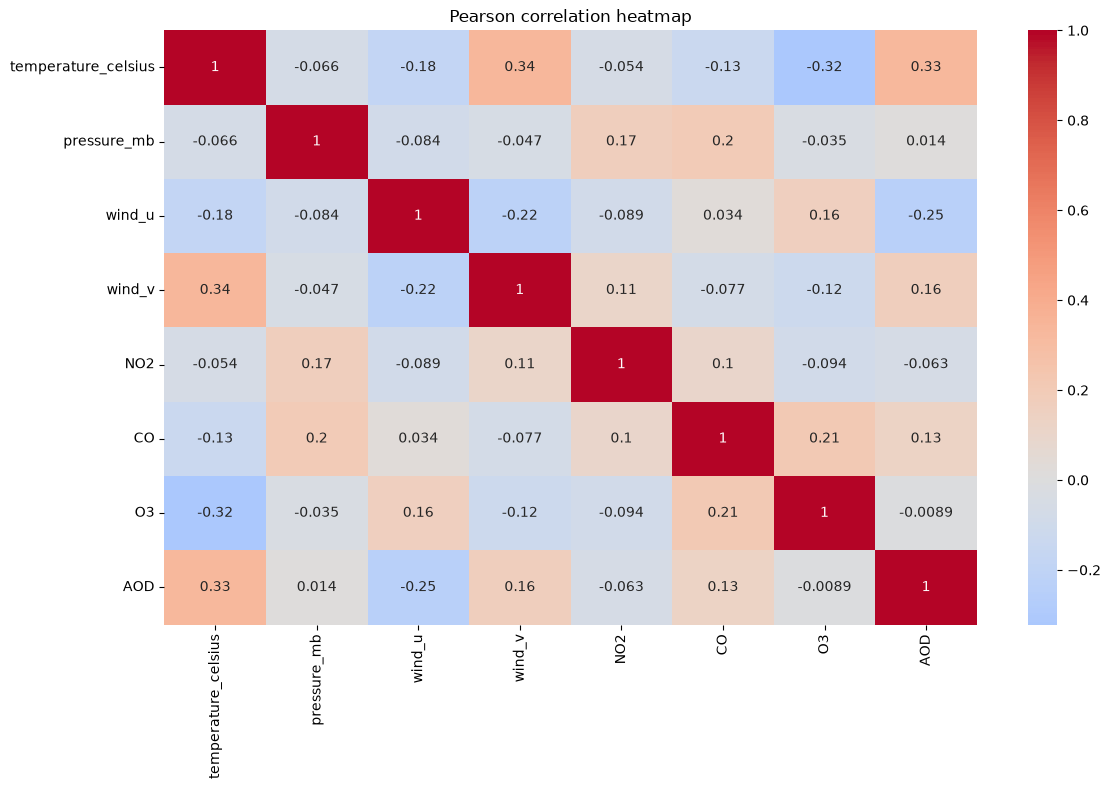

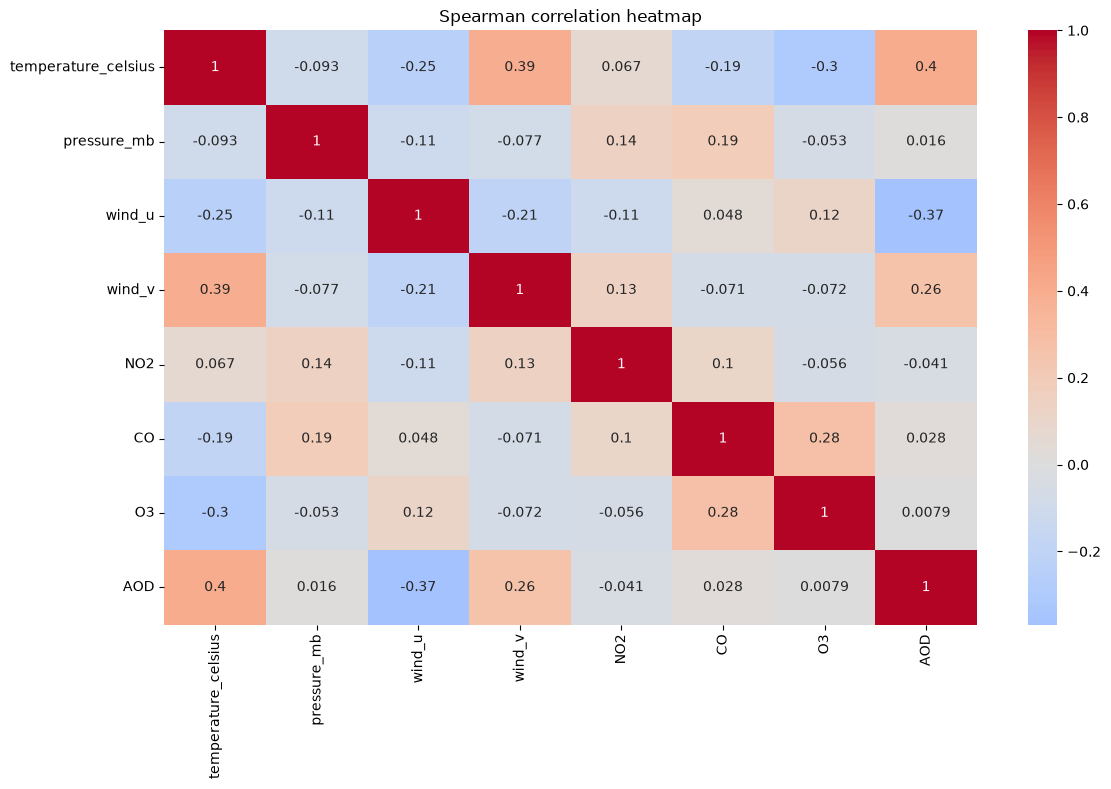

In [ ]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("Pearson correlation heatmap")
plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 8))

sns.heatmap(
    spearman_corr,
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("Spearman correlation heatmap")
plt.tight_layout()
plt.show()

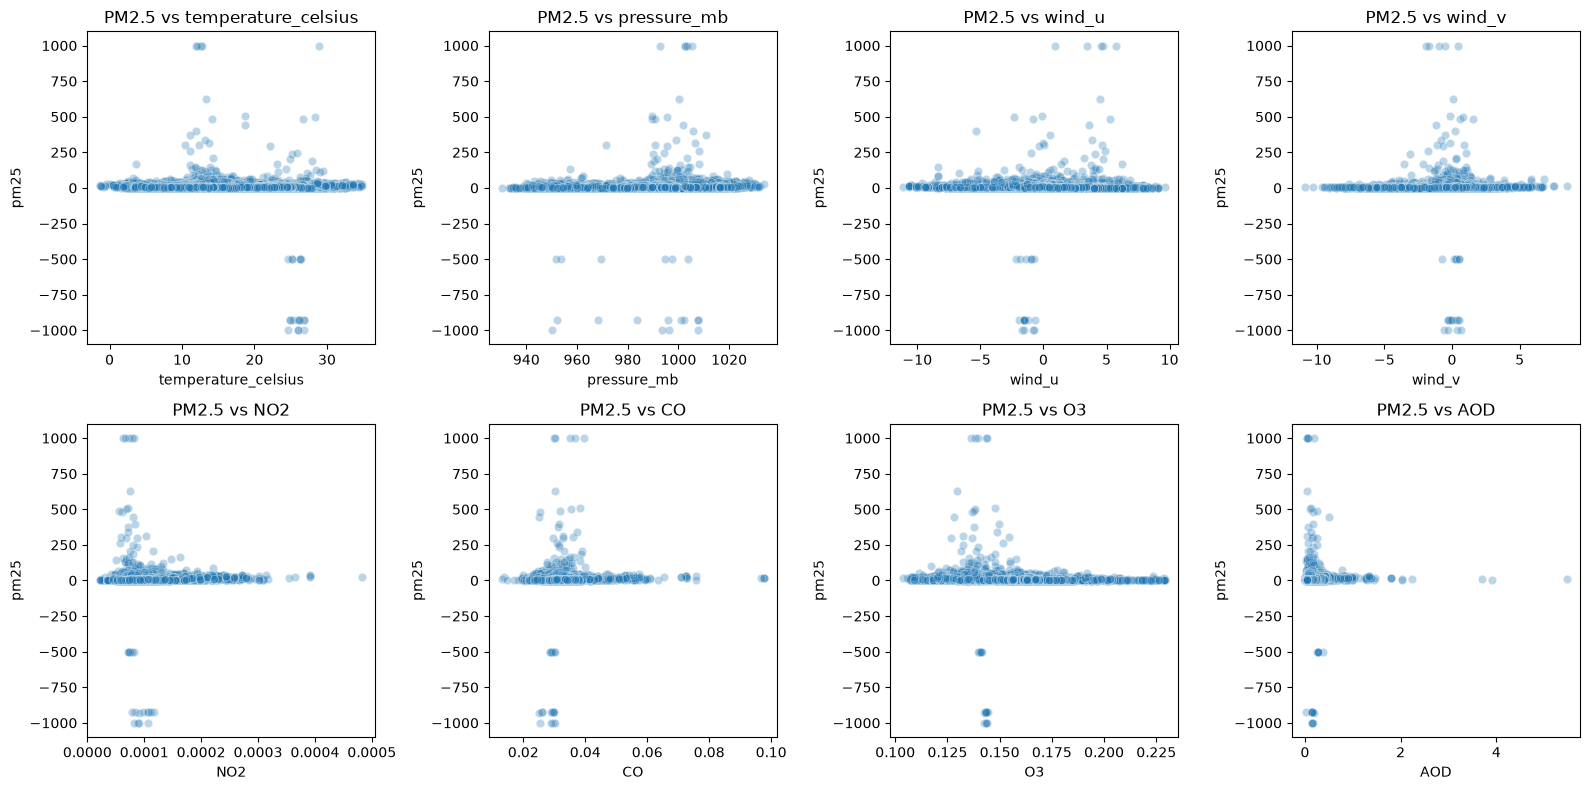

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(predictors):
    sns.scatterplot(
        data=df,
        x=col,
        y=target,
        alpha=0.3,
        ax=axes[i]
    )

    axes[i].set_title(f"PM2.5 vs {col}")

plt.tight_layout()
plt.show()

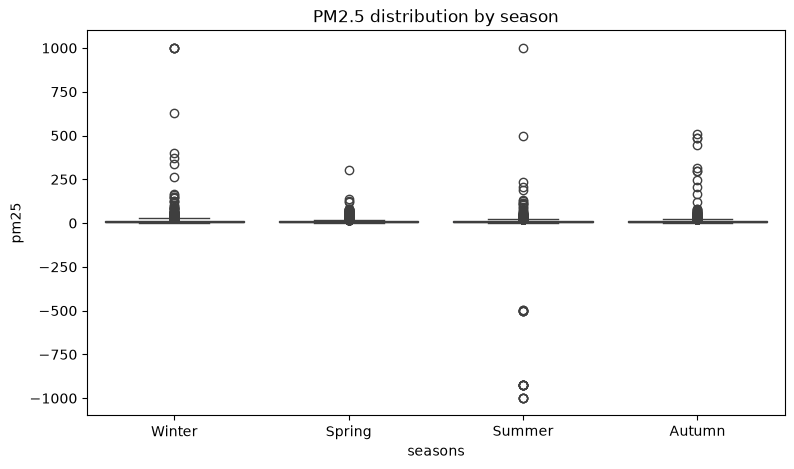


Average PM2.5 by seasons:
seasons
Autumn     9.10
Spring     7.99
Summer     8.32
Winter    11.42
Name: pm25, dtype: float64


In [ ]:
df["month"] = df["date"].dt.month

seasons = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

df["seasons"] = df["month"].map(seasons)

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="seasons",
    y=target,
    order=["Winter", "Spring", "Summer", "Autumn"]
)

plt.title("PM2.5 distribution by season")
plt.show()

print("\nAverage PM2.5 by seasons:")
print(df.groupby("seasons")[target].mean().round(2))

PM2.5 skewness: -10.53


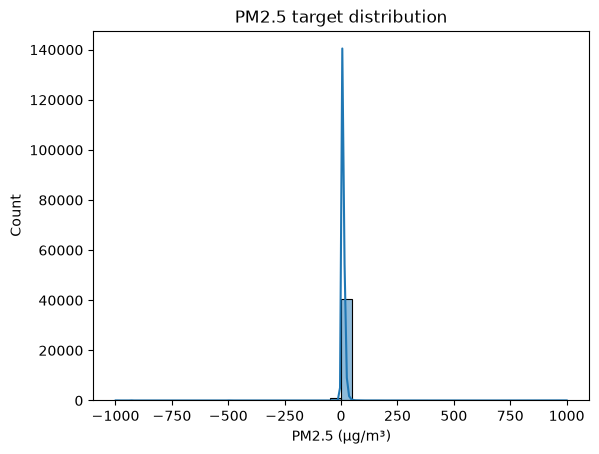

In [ ]:
print(
    "PM2.5 skewness:",
    round(df[target].skew(), 2)
)

sns.histplot(
    data=df,
    x=target,
    bins=40,
    kde=True
)

plt.title("PM2.5 target distribution")
plt.xlabel("PM2.5 (µg/m³)")
plt.show()

In [ ]:
prop_25 = (df[target] > 25).mean() * 100
prop_50 = (df[target] > 50).mean() * 100

print("\nPM2.5 pollution thresholds:")
print(
    "Proportion of PM2.5 > 25:",
    round(prop_25, 2),
    "%"
)

print(
    "Proportion of PM2.5 > 50:",
    round(prop_50, 2),
    "%"
)


PM2.5 pollution thresholds:
Proportion of PM2.5 > 25: 2.95 %
Proportion of PM2.5 > 50: 0.3 %


In [ ]:
X_lof = df[predictors].copy()

lof_imputer = SimpleImputer(
    strategy="median"
)

X_lof_imputed = lof_imputer.fit_transform(
    X_lof
)

lof_scaler = StandardScaler()

X_lof_scaled = lof_scaler.fit_transform(
    X_lof_imputed
)

lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination="auto",
    n_jobs=-1
)

lof_predictions = lof.fit_predict(
    X_lof_scaled
)

n_out_lof = (
    lof_predictions == -1
).sum()

pct_out_lof = (
    n_out_lof / len(df) * 100
)

print("LOF potential outliers:", n_out_lof)
print(
    "LOF outlier percentage:",
    round(pct_out_lof, 2),
    "%"
)

LOF potential outliers: 194
LOF outlier percentage: 0.47 %


In [ ]:
X_vif = df[predictors].copy()

X_vif = SimpleImputer(
    strategy="median"
).fit_transform(X_vif)

X_vif = pd.DataFrame(
    StandardScaler().fit_transform(X_vif),
    columns=predictors
)

vif_results = {}

for i, predictor in enumerate(predictors):

    try:
        vif_results[predictor] = (
            variance_inflation_factor(
                X_vif.values,
                i
            )
        )

    except (ValueError, np.linalg.LinAlgError):
        vif_results[predictor] = np.nan

print("\nVIF results:")

for predictor, value in vif_results.items():
    print(
        predictor,
        ":",
        round(value, 3)
        if pd.notna(value)
        else np.nan
    )


VIF results:
temperature_celsius : 1.399
pressure_mb : 1.08
wind_u : 1.145
wind_v : 1.187
NO2 : 1.079
CO : 1.142
O3 : 1.193
AOD : 1.236
